# Catalogue EDA

Compare the original Zenodo catalogue with the selected Hugging Face source.
The questions are practical: which records can support the MVP, what is lost
during deduplication, and do the earlier EDA conclusions hold?

Counts use complete files; sampling is used only for the scatter plot.
Reports are generated locally and are not needed as input. This notebook measures catalogue
quality, not recommendation quality or current Spotify availability.

In [1]:
import ast
import hashlib
import json
import platform
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent

raw_dir = root / "data" / "raw"
report_dir = root / "reports" / "eda_v2"
report_dir.mkdir(parents=True, exist_ok=True)

# Both inputs are pinned to a published checksum, so the notebook fails loudly
# instead of analysing a different revision.
sources = {
    "zenodo": {
        "path": raw_dir / "tracks.csv",
        "url": "https://zenodo.org/records/11453410",
        "algorithm": "md5",
        "checksum": "c32dffb8f9a62fec8c5892b464d7ea42",
        "rename": {"name": "title", "track_artists": "artists"},
    },
    "hf": {
        "path": raw_dir / "spotify_tracks_hf.csv",
        "url": "https://huggingface.co/datasets/maharshipandya/spotify-tracks-dataset/resolve/635b034f69257814eff850a5c2b3346fe458134f/dataset.csv",
        "algorithm": "sha256",
        "checksum": "b202fa49909b2d5cef71a04b1d21243cfeb36414535f2ca9272aa646721177bd",
        "rename": {"track_name": "title", "track_genre": "genres"},
    },
}

versions = {
    "python": platform.python_version(),
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "matplotlib": matplotlib.__version__,
}
display(pd.Series(versions, name="version").to_frame())


,version
python,3.12.3
pandas,3.0.3
numpy,2.0.2
matplotlib,3.9.2


## Source checks and loading

Files are local and excluded from Git. Zenodo's MD5 is published by the
source; the HF SHA256 records the previously downloaded, revision-pinned CSV.
Read only the columns used by the app. Preserve literal names such as `NA`;
strip surrounding whitespace and treat blank fields as missing. Count numeric
conversion failures separately from missing and out-of-range values.

In [2]:
numeric_columns = [
    "duration_ms",
    "energy",
    "tempo",
    "valence",
    "danceability",
    "instrumentalness",
    "acousticness",
]
unit_features = [
    column for column in numeric_columns if column not in {"duration_ms", "tempo"}
]
columns = ["track_id", "title", "artists", "genres", "explicit", *numeric_columns]
frames = {}
parse_failures = {}
provenance = []

for source_name, source in sources.items():
    with source["path"].open("rb") as stream:
        checksum = hashlib.file_digest(stream, source["algorithm"]).hexdigest()
    if checksum != source["checksum"]:
        raise ValueError(f"Unexpected source checksum: {source['path']}")

    # The rename map is written as new -> old, while usecols needs old names.
    column_names = {new: old for old, new in source["rename"].items()}
    source_columns = [column_names.get(column, column) for column in columns]
    frame = pd.read_csv(
        source["path"], usecols=source_columns, dtype="string", keep_default_na=False
    ).rename(columns=source["rename"])
    for column in columns:
        frame[column] = frame[column].str.strip().replace("", pd.NA)

    conversion_failures = {}
    for column in numeric_columns:
        numeric = pd.to_numeric(frame[column], errors="coerce").astype("float64")
        conversion_failures[column] = int(
            (frame[column].notna() & numeric.isna()).sum()
        )
        frame[column] = numeric

    frames[source_name] = frame
    parse_failures[source_name] = conversion_failures
    provenance.append(
        {
            "source": source_name,
            "url": source["url"],
            "bytes": source["path"].stat().st_size,
            "algorithm": source["algorithm"],
            "checksum": checksum,
        }
    )

display(pd.DataFrame(provenance)[["source", "bytes", "algorithm", "checksum"]])
display(pd.DataFrame(parse_failures).rename_axis("numeric conversion failures"))


,source,bytes,algorithm,checksum
0,zenodo,931386809,md5,c32dffb8f9a62fec8c5892b464d7ea42
1,hf,20118244,sha256,b202fa49909b2d5cef71a04b1d21243cfeb36414535f2c...


,zenodo,hf
numeric conversion failures,,
duration_ms,0,0
energy,0,0
tempo,0,0
valence,0,0
danceability,0,0
instrumentalness,0,0
acousticness,0,0


## Genres and record validity

Zenodo stores genres as serialized lists; HF has one label per row. Keep the
union of labels for each track ID. A missing field and an empty list both
mean that no genre is available, but they are reported separately.

Positive finite duration and energy in [0,1] are required for the example
playlist. A zero energy value is valid. Zero BPM is unavailable tempo, not a
reason to reject a track when no tempo constraint is requested.

In [3]:
def parse_genres(text):
    values = ast.literal_eval(text)
    if not isinstance(values, list) or not all(
        isinstance(value, str) for value in values
    ):
        raise ValueError(f"Expected a list of genre names: {text!r}")
    return sorted({value.strip().casefold() for value in values if value.strip()})


def numeric_validity(frame):
    valid = pd.DataFrame(index=frame.index)
    for column in numeric_columns:
        finite = np.isfinite(frame[column])
        if column in unit_features:
            valid[column] = finite & frame[column].between(0, 1)
        else:
            valid[column] = finite & frame[column].gt(0)
    return valid


def track_view(frame):
    # Keep the best row per ID: valid duration first, then field coverage, then
    # the original source order.
    ranked = frame.loc[frame.track_id.notna()].copy()
    ranked["_valid_duration"] = np.isfinite(ranked.duration_ms) & ranked.duration_ms.gt(
        0
    )
    ranked["_coverage"] = ranked[columns].notna().sum(axis=1)
    ranked["_row"] = np.arange(len(ranked))
    return (
        ranked.sort_values(
            ["_valid_duration", "_coverage", "_row"], ascending=[False, False, True]
        )
        .drop_duplicates("track_id")
        .drop(columns=["_valid_duration", "_coverage", "_row"])
    )


def usable_tracks(frame, genre_ids):
    valid = numeric_validity(frame)
    has_id = frame.track_id.str.fullmatch(r"[A-Za-z0-9]{22}", na=False)
    has_artist = frame.artists.fillna("").str.strip().ne("")
    has_title = frame.title.fillna("").str.strip().ne("")
    return (
        has_id
        & valid.duration_ms
        & valid.energy
        & has_artist
        & has_title
        & frame.track_id.isin(genre_ids)
    )


genre_map = {
    text: parse_genres(text) for text in frames["zenodo"].genres.dropna().unique()
}
genre_pairs = {}
zenodo_pairs = frames["zenodo"][["track_id", "genres"]].drop_duplicates().copy()
zenodo_pairs["genre"] = zenodo_pairs.genres.map(genre_map)
genre_pairs["zenodo"] = (
    zenodo_pairs[["track_id", "genre"]].explode("genre").dropna().drop_duplicates()
)
hf_pairs = frames["hf"][["track_id", "genres"]].dropna().copy()
hf_pairs["genre"] = hf_pairs.genres.str.casefold()
genre_pairs["hf"] = hf_pairs[["track_id", "genre"]].drop_duplicates()


## Unique-track audit

Prefer a row with valid duration, then more present fields, then source order.
This reproducible EDA convention does not resolve conflicting observations.
Count numeric and text disagreements before selecting representatives.
Duplicate counts below concern the selected app fields, not the source's
export index or unrelated metadata.

In [4]:
catalogues = {}
summaries = {}
conflicts = {}
quality = {}

for source_name, frame in frames.items():
    tracks = track_view(frame)
    catalogues[source_name] = tracks

    repeated = frame.loc[
        frame.track_id.notna() & frame.track_id.duplicated(keep=False)
    ]
    observed = repeated.groupby("track_id")[
        numeric_columns + ["artists", "title", "explicit"]
    ].nunique()
    conflicts[source_name] = observed.gt(1).sum().astype(int)

    valid = numeric_validity(tracks)
    genre_ids = set(genre_pairs[source_name].track_id)
    has_genre = tracks.track_id.isin(genre_ids)
    has_names = tracks.artists.notna() & tracks.title.notna()
    id_valid = tracks.track_id.str.fullmatch(r"[A-Za-z0-9]{22}", na=False)
    invalid_numeric = {
        column: int((tracks[column].notna() & ~valid[column]).sum())
        for column in numeric_columns
    }
    empty_genre_rows = 0
    if source_name == "zenodo":
        empty_values = [text for text, values in genre_map.items() if not values]
        empty_genre_rows = int(frame.genres.isin(empty_values).sum())

    summaries[source_name] = {
        "raw_rows": len(frame),
        "unique_tracks": len(tracks),
        "missing_id_rows": int(frame.track_id.isna().sum()),
        "invalid_unique_ids": int((~id_valid).sum()),
        "repeated_id_rows": int(
            frame.loc[frame.track_id.notna(), "track_id"].duplicated().sum()
        ),
        "duplicate_rows_selected_fields": int(frame[columns].duplicated().sum()),
        "missing_pct_unique_tracks": tracks[columns]
        .isna()
        .mean()
        .mul(100)
        .round(4)
        .to_dict(),
        "numeric_parse_failures_rows": parse_failures[source_name],
        "invalid_numeric_unique_tracks": invalid_numeric,
        "conflicting_ids_by_field": conflicts[source_name].to_dict(),
        "genre_labels": int(genre_pairs[source_name].genre.nunique()),
        "tracks_with_genres": int(has_genre.sum()),
        "empty_genre_list_rows": empty_genre_rows,
        "eligibility": {
            "positive_finite_duration": int(valid.duration_ms.sum()),
            "duration_and_energy": int((valid.duration_ms & valid.energy).sum()),
            "duration_energy_and_genre": int(
                (valid.duration_ms & valid.energy & has_genre).sum()
            ),
            "duration_energy_artist_title": int(
                (valid.duration_ms & valid.energy & has_names).sum()
            ),
            "duration_energy_genre_artist_title": int(
                usable_tracks(tracks, genre_ids).sum()
            ),
        },
    }
    quality[source_name] = {
        "Known duration": 100 * valid.duration_ms.mean(),
        "Known energy": 100 * valid.energy.mean(),
        "Known artist": 100 * tracks.artists.notna().mean(),
        "Known title": 100 * tracks.title.notna().mean(),
        "Known genre": 100 * has_genre.mean(),
        "MVP usable": 100 * usable_tracks(tracks, genre_ids).mean(),
    }

counts = pd.DataFrame(
    {
        source_name: {
            "raw rows": source_summary["raw_rows"],
            "unique tracks": source_summary["unique_tracks"],
            "repeated ID rows": source_summary["repeated_id_rows"],
            "duplicate rows in selected fields": source_summary[
                "duplicate_rows_selected_fields"
            ],
            "tracks with genres": source_summary["tracks_with_genres"],
            "genre labels": source_summary["genre_labels"],
            "MVP usable tracks": source_summary["eligibility"][
                "duration_energy_genre_artist_title"
            ],
        }
        for source_name, source_summary in summaries.items()
    }
)
display(counts)
display(pd.DataFrame(conflicts).rename_axis("IDs with conflicting observed values"))
display(
    pd.DataFrame(
        {
            source_name: source_summary["invalid_numeric_unique_tracks"]
            for source_name, source_summary in summaries.items()
        }
    ).rename_axis("invalid nonmissing values")
)
display(
    pd.DataFrame(
        {
            source_name: source_summary["missing_pct_unique_tracks"]
            for source_name, source_summary in summaries.items()
        }
    )
    .round(2)
    .rename_axis("missing, % of unique tracks")
)
print("Zenodo empty genre-list rows:", summaries["zenodo"]["empty_genre_list_rows"])


,zenodo,hf
raw rows,899702,114000
unique tracks,899702,89741
repeated ID rows,0,24259
duplicate rows in selected fields,0,450
tracks with genres,721337,89741
genre labels,5888,114
MVP usable tracks,810,89740


,zenodo,hf
IDs with conflicting observed values,,
duration_ms,0,0
energy,0,0
tempo,0,0
valence,0,0
danceability,0,0
instrumentalness,0,0
acousticness,0,0
artists,0,0
title,0,0


,zenodo,hf
invalid nonmissing values,,
duration_ms,19,1
energy,0,0
tempo,529,157
valence,0,0
danceability,0,0
instrumentalness,0,0
acousticness,0,0


,zenodo,hf
"missing, % of unique tracks",,
track_id,0.00,0.0
title,0.05,0.0
artists,88.89,0.0
genres,0.80,0.0
explicit,0.00,0.0
duration_ms,99.22,0.0
energy,0.05,0.0
tempo,0.05,0.0
valence,0.05,0.0


Zenodo empty genre-list rows: 171179


## Coverage and feature distributions

Coverage uses all distinct IDs. Feature plots use the HF tracks eligible for
the duration/energy/artist/title/genre demo. Mask invalid optional features
before plotting or correlation. The duration histogram omits the upper 0.5%
for readability only; those tracks remain in the audit and eligibility counts.

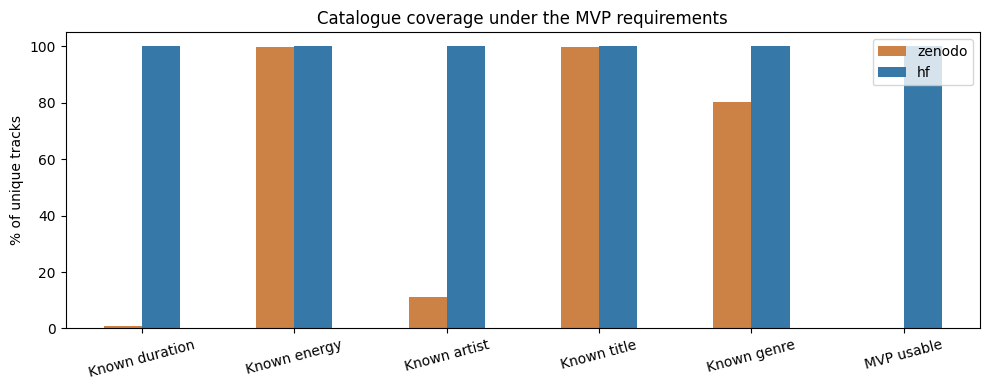

,duration_ms,energy,tempo,valence,danceability,instrumentalness,acousticness
count,89740.000,89740.000,89583.000,89740.000,89740.000,89740.000,89740.000
mean,229144.366,0.634,122.272,0.469,0.562,0.173,0.328
std,112945.780,0.257,29.707,0.263,0.177,0.324,0.338
min,8586.000,0.000,30.200,0.000,0.000,0.000,0.000
1%,61871.850,0.027,66.425,0.033,0.123,0.000,0.000
50%,213295.500,0.676,122.021,0.457,0.576,0.000,0.188
99%,546010.980,0.993,193.670,0.965,0.904,0.958,0.992
max,5237295.000,1.000,243.372,0.995,0.985,1.000,0.996


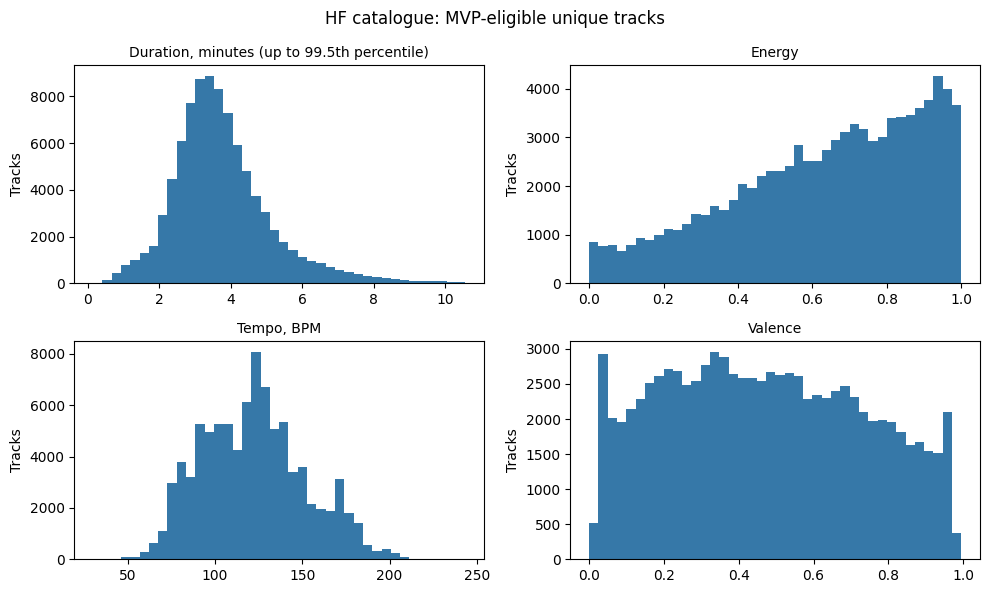

HF optional tempo values masked: 157


In [5]:
fig, ax = plt.subplots(figsize=(10, 4))
pd.DataFrame(quality).plot.bar(ax=ax, color=["#cc8245", "#3678a8"], rot=15)
ax.set_ylabel("% of unique tracks")
ax.set_ylim(0, 105)
ax.set_title("Catalogue coverage under the MVP requirements")
fig.tight_layout()
fig.savefig(report_dir / "coverage.png", dpi=130)
plt.show()
plt.close(fig)

hf_tracks = catalogues["hf"]
hf_ready = hf_tracks.loc[
    usable_tracks(hf_tracks, set(genre_pairs["hf"].track_id))
].copy()
clean_features = hf_ready[numeric_columns].where(numeric_validity(hf_ready))
display(clean_features.describe(percentiles=[0.01, 0.5, 0.99]).round(3))

fig, axes = plt.subplots(2, 2, figsize=(10, 6))
durations = clean_features.duration_ms / 60000
duration_limit = durations.quantile(0.995)
for ax, column, title in zip(
    axes.flat,
    ["duration_ms", "energy", "tempo", "valence"],
    ["Duration, minutes (up to 99.5th percentile)", "Energy", "Tempo, BPM", "Valence"],
):
    values = clean_features[column].dropna()
    if column == "duration_ms":
        values = durations.loc[durations.le(duration_limit)]
    ax.hist(values, bins=40, color="#3678a8")
    ax.set_title(title, fontsize=10)
    ax.set_ylabel("Tracks")
fig.suptitle("HF catalogue: MVP-eligible unique tracks")
fig.tight_layout()
fig.savefig(report_dir / "distributions.png", dpi=130)
plt.show()
plt.close(fig)
print("HF optional tempo values masked:", int(clean_features.tempo.isna().sum()))


,energy,tempo,valence,danceability,acousticness,instrumentalness
energy,1.000,0.249,0.256,0.144,-0.733,-0.181
tempo,0.249,1.000,0.079,-0.045,-0.220,-0.047
valence,0.256,0.079,1.000,0.493,-0.104,-0.331
danceability,0.144,-0.045,0.493,1.000,-0.177,-0.195
acousticness,-0.733,-0.220,-0.104,-0.177,1.000,0.096
instrumentalness,-0.181,-0.047,-0.331,-0.195,0.096,1.000


,energy,tempo,valence,danceability,acousticness,instrumentalness
pairwise sample counts,,,,,,
energy,89740,89583,89740,89740,89740,89740
tempo,89583,89583,89583,89583,89583,89583
valence,89740,89583,89740,89740,89740,89740
danceability,89740,89583,89740,89740,89740,89740
acousticness,89740,89583,89740,89740,89740,89740
instrumentalness,89740,89583,89740,89740,89740,89740


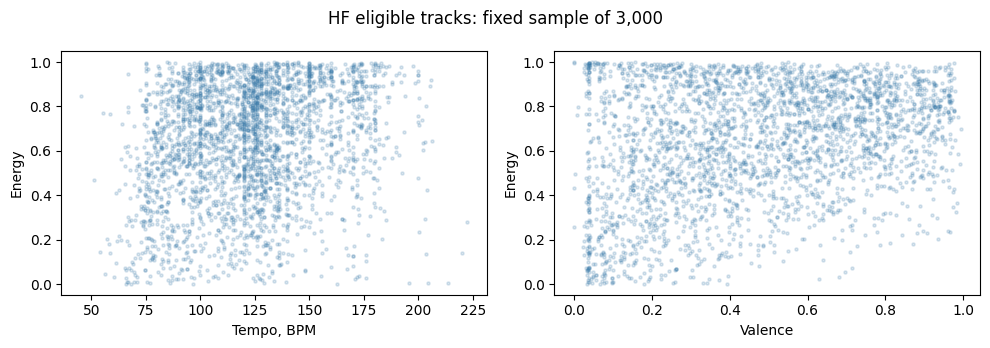

,eligible unique tracks
genre,
acoustic,1000
british,1000
country,1000
disco,1000
electronic,1000
emo,1000
funk,1000
garage,1000
indie-pop,1000


In [6]:
feature_columns = [
    "energy",
    "tempo",
    "valence",
    "danceability",
    "acousticness",
    "instrumentalness",
]
correlations = clean_features[feature_columns].corr()
pair_counts = clean_features[feature_columns].notna().astype("int64")
pair_counts = pair_counts.T @ pair_counts
display(correlations.round(3))
display(pair_counts.rename_axis("pairwise sample counts"))

complete = clean_features[["energy", "tempo", "valence"]].dropna()
sample = complete.sample(n=min(3000, len(complete)), random_state=42)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, column, label in zip(axes, ["tempo", "valence"], ["Tempo, BPM", "Valence"]):
    ax.scatter(sample[column], sample.energy, s=5, alpha=0.18, color="#3678a8")
    ax.set_xlabel(label)
    ax.set_ylabel("Energy")
fig.suptitle(f"HF eligible tracks: fixed sample of {len(sample):,}")
fig.tight_layout()
fig.savefig(report_dir / "relationships.png", dpi=130)
plt.show()
plt.close(fig)

ready_genres = genre_pairs["hf"].loc[genre_pairs["hf"].track_id.isin(hf_ready.track_id)]
display(
    ready_genres.genre.value_counts()
    .head(15)
    .rename("eligible unique tracks")
    .to_frame()
)


In [7]:
z = summaries["zenodo"]
h = summaries["hf"]
summary = {
    "sources": provenance,
    "versions": versions,
    "catalogues": summaries,
    "hf_eligible_tracks": len(hf_ready),
    "hf_tempo_masked_in_eligible_tracks": int(clean_features.tempo.isna().sum()),
    "hf_correlations": correlations.to_dict(),
    "hf_correlation_pair_counts": pair_counts.to_dict(),
}
(report_dir / "summary.json").write_text(
    json.dumps(summary, indent=2, allow_nan=False) + "\n", encoding="utf-8"
)

findings = "\n".join(
    [
        "# Catalogue findings",
        "",
        f"Zenodo: {z['raw_rows']:,} rows and {z['unique_tracks']:,} unique IDs; {z['missing_pct_unique_tracks']['duration_ms']:.2f}% lack duration and {z['missing_pct_unique_tracks']['artists']:.2f}% lack artist names.",
        f"Only {z['eligibility']['duration_energy_genre_artist_title']:,} tracks satisfy the duration/energy/genre/artist/title requirements.",
        "",
        f"HF: {h['raw_rows']:,} rows, {h['unique_tracks']:,} unique IDs, {len(hf_ready):,} usable tracks and {h['genre_labels']:,} labels.",
        "Use this source for the MVP. Deduplicate by ID and preserve the union of genre labels. Parse artist credits on semicolons.",
        "",
        "Energy zero is valid; tempo zero is unavailable. Missing optional tempo does not invalidate a duration/energy request.",
        "Feature values are proxies for perceived music properties. Catalogue IDs do not establish current playback availability.",
        "No data was imputed, no application database was prepared, and no recommendation model or MPD evaluation was run.",
    ]
)
(report_dir / "findings.md").write_text(findings + "\n", encoding="utf-8")
print(findings)


# Catalogue findings

Zenodo: 899,702 rows and 899,702 unique IDs; 99.22% lack duration and 88.89% lack artist names.
Only 810 tracks satisfy the duration/energy/genre/artist/title requirements.

HF: 114,000 rows, 89,741 unique IDs, 89,740 usable tracks and 114 labels.
Use this source for the MVP. Deduplicate by ID and preserve the union of genre labels. Parse artist credits on semicolons.

Energy zero is valid; tempo zero is unavailable. Missing optional tempo does not invalidate a duration/energy request.
Feature values are proxies for perceived music properties. Catalogue IDs do not establish current playback availability.
No data was imputed, no application database was prepared, and no recommendation model or MPD evaluation was run.
